<a href="https://colab.research.google.com/github/isiahndanzia/CSCE1015/blob/main/Copy_of_INFO4670_Assignment_SMS_Spam_v4.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 12: Assignment 4 — SMS Spam Detection

**Goal:** Apply the six-step classification workflow to a real dataset.
Predict whether an SMS message is spam or legitimate (ham) using text-based features.

---

## I. Assignment Objective

By completing this assignment, you will:
- Follow a complete classification pipeline on real-world data
- Engineer binary features from raw text
- Train and evaluate a Decision Tree and a Naive Bayes classifier
- Interpret a confusion matrix and choose the right evaluation metric
- Analyze model performance and reflect on possible improvements

---

## II. Dataset

**Source:** UCI SMS Spam Collection (5,572 real SMS messages, no login required)

| Column | Description | Example |
|---|---|---|
| `label` | Class label | `spam` or `ham` |
| `message` | Raw SMS text | "WINNER!! You have been selected..." |
| `spam` | Encoded label (1 = spam, 0 = ham) | 1 |

Load it with one line — no file upload needed:
```python
url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
```

---

## III. Grading Rubric (Total = 70 points)

| Section | What is graded | Points |
|---|---|---|
| Step 1 — Problem definition | Q1a + Q1b + Q1c (written) | 5 |
| Step 2 — Explore the data | Code runs correctly (2B, 2C, 2D) | 10 |
| Step 3 — Feature engineering | Code (3B, 3C) + Q3a + Q3b + Q3c (written) | 15 |
| Step 4 — Split the data | Code (4A) + Q4a + Q4b (written) | 5 |
| Step 5 — Train models | Code: 5A + 5B + 5C + 5D (3 pts each) | 12|
| Step 6 — Code (6A + 6B + 6C) | Each code block runs correctly (4 pts each) | 12 |
| Step 6 — Written (Q6a–Q6d) | Q6a (2) + Q6b (3) + Q6c (3) + Q6d (3) | 11 |
| **Total** | | **70** |

---

## IV. Steps to Complete

Follow the steps below in order.
Each code cell starts with `# Write your code here` — replace it with your implementation.


---
### Setup — Run this cell first (provided)

In [1]:
# This cell is provided — run it before starting
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import re
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.naive_bayes import BernoulliNB
from sklearn.metrics import (
    confusion_matrix, accuracy_score, precision_score,
    recall_score, f1_score, ConfusionMatrixDisplay
)
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
import warnings
warnings.filterwarnings('ignore')
np.random.seed(42)
print('Setup complete!')


Setup complete!


---
## Step 1 — Define the Problem

Before writing any code, answer the questions below.
Your answers here should guide every metric decision you make in Step 6.

**Context:**
A mobile carrier wants an automated classifier to flag spam SMS messages
before they reach users. The two possible errors are:

| Error | What happens |
|---|---|
| False Positive | A real (ham) message gets blocked |
| False Negative | A spam message reaches the user |

### Q1 — Problem Definition *(10 points)*

**Q1a.** Which error is more costly in a real spam filter — False Positive or False Negative?
Give one concrete real-world consequence for each.

*Your answer:*
> ...  A false positive is more costly because blocking real messages may lead to important information being missed. A false negative letting a spam text through can just be ignored and is not as impactful

**Q1b.** Based on Q1a, which metric should be your primary evaluation target?
Choose one: **Precision**, **Recall**, or **F1-Score**. Explain why.

*Your answer:*
> ... Precision is the primary evaluation target because Its the most important thing to me

**Q1c.** The spam rate in this dataset is about 13%.
What accuracy would a dummy model that always predicts "ham" achieve?
Is that number still misleading? Why?

*Your answer:*
> ...
With about 13% spam, a model that always predicts ham would achieve about 87% accuracy. The actual dataset has 4,825 ham messages out of 5,572, giving 86.59% accuracy. This is misleading because the model catches no spam, so its spam recall and F1 score are both zero.

---
## Step 2 — Load and Explore the Data

### Step 2A — Load the dataset



In [2]:
import urllib.request, zipfile, io

url = 'https://archive.ics.uci.edu/ml/machine-learning-databases/00228/smsspamcollection.zip'
print('Downloading UCI SMS Spam Collection...')
with urllib.request.urlopen(url) as r:
    zf = zipfile.ZipFile(io.BytesIO(r.read()))
    with zf.open('SMSSpamCollection') as f:
        raw = pd.read_csv(f, sep='\t', header=None, names=['label', 'message'])

raw['spam'] = (raw['label'] == 'spam').astype(int)
print(f'Loaded: {len(raw)} messages')
raw.head(6)


Loaded: 5572 messages


,label,message,spam
0,ham,"Go until jurong point, crazy.. Available only ...",0
1,ham,Ok lar... Joking wif u oni...,0
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...,1
3,ham,U dun say so early hor... U c already then say...,0
4,ham,"Nah I don't think he goes to usf, he lives aro...",0
5,spam,FreeMsg Hey there darling it's been 3 week's n...,1


### Step 2B — Class distribution

**Hint:** Print the count and percentage of spam and ham messages.
Plot a bar chart with spam count in red and ham count in blue.
Also run a dummy model (predict all ham) and print its Accuracy, Recall, and F1.
This proves the Accuracy Trap from Lecture 8.


Class distribution:
  Ham  (0): 4,825  (86.6%)
  Spam (1): 747  (13.4%)

Dummy model (always predict ham):
  Accuracy  = 86.6%  <-- misleadingly high
  Recall    = 0.0%  <-- catches zero spam
  F1-Score  = 0.0%


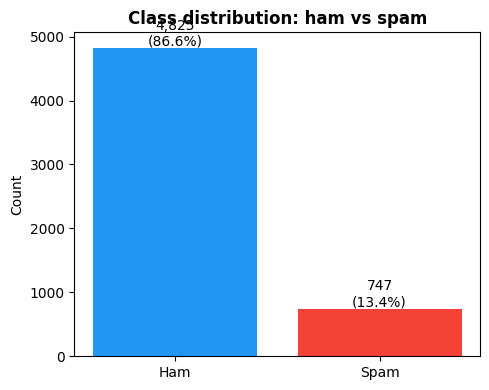

In [3]:
# Write your code here
spam_count = raw['spam'].sum()
ham_count  = (raw['spam'] == 0).sum()
spam_rate  = raw['spam'].mean()

print('Class distribution:')
print(f'  Ham  (0): {ham_count:,}  ({1-spam_rate:.1%})')
print(f'  Spam (1): {spam_count:,}  ({spam_rate:.1%})')
print()

# Prove the accuracy trap with a dummy model
y_all   = raw['spam'].values
y_dummy = np.zeros(len(y_all), dtype=int)
print(f'Dummy model (always predict ham):')
print(f'  Accuracy  = {accuracy_score(y_all, y_dummy):.1%}  <-- misleadingly high')
print(f'  Recall    = {recall_score(y_all, y_dummy, zero_division=0):.1%}  <-- catches zero spam')
print(f'  F1-Score  = {f1_score(y_all, y_dummy, zero_division=0):.1%}')

fig, ax = plt.subplots(figsize=(5, 4))
ax.bar(['Ham', 'Spam'], [ham_count, spam_count], color=['#2196F3', '#F44336'])
ax.set_ylabel('Count')
ax.set_title('Class distribution: ham vs spam', fontweight='bold')
for i, v in enumerate([ham_count, spam_count]):
    ax.text(i, v + 30, f'{v:,}\n({v/len(raw):.1%})', ha='center', fontsize=10)
plt.tight_layout()
plt.show()


### Step 2C — Read the raw text

**Hint:** Print 5 spam examples and 5 ham examples.
Limit each message to 130 characters using string slicing.


In [4]:
print('=== SPAM examples ===')
for i, msg in enumerate(raw[raw['spam']==1]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()

print('=== HAM examples ===')
for i, msg in enumerate(raw[raw['spam']==0]['message'].head(5), 1):
    print(f'{i}. {msg[:130]}')
    print()


=== SPAM examples ===
1. Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std txt rate)T&C's 

2. FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX std chgs to s

3. WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 09061701461. Claim code 

4. Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call The Mobile Updat

5. SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs apply Reply HL 

=== HAM examples ===
1. Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...

2. Ok lar... Joking wif u oni...

3. U dun say so early hor... U c already then say...

4. Nah I don't think he goes to usf, he lives around here though

5. Even my b

### Step 2D — Message length analysis

**Hint:** Add a column `msg_length = message.str.len()`.
Print average length for spam and ham.
Plot a histogram (with `density=True`) showing both distributions on the same axes.


Average message length:
  Ham  : 71 characters
  Spam : 139 characters


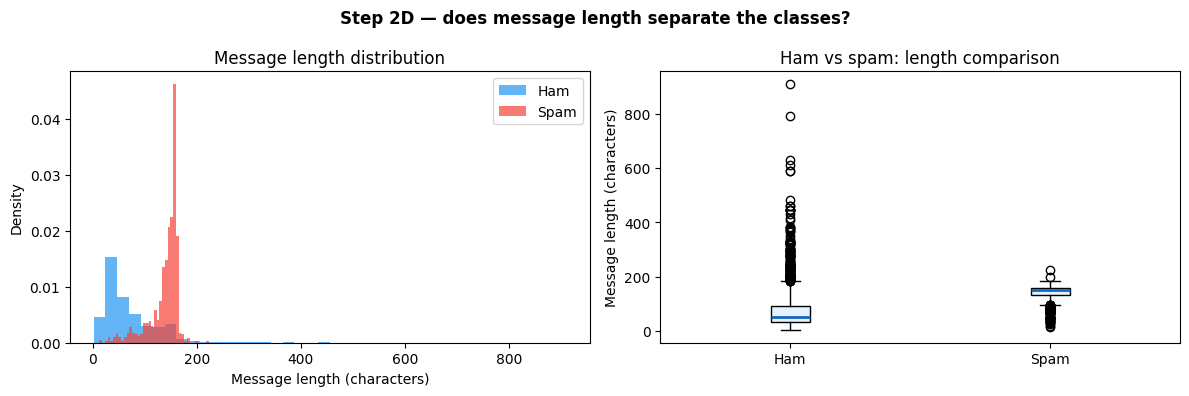

In [ ]:
raw['msg_length'] = raw['message'].str.len()

print('Average message length:')
print(f'  Ham  : {raw[raw["spam"]==0]["msg_length"].mean():.0f} characters')
print(f'  Spam : {raw[raw["spam"]==1]["msg_length"].mean():.0f} characters')

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(raw[raw['spam']==0]['msg_length'], bins=40, alpha=0.7,
             color='#2196F3', label='Ham', density=True)
axes[0].hist(raw[raw['spam']==1]['msg_length'], bins=40, alpha=0.7,
             color='#F44336', label='Spam', density=True)
axes[0].set_xlabel('Message length (characters)')
axes[0].set_ylabel('Density')
axes[0].set_title('Message length distribution')
axes[0].legend()

axes[1].boxplot(
    [raw[raw['spam']==0]['msg_length'], raw[raw['spam']==1]['msg_length']],
    labels=['Ham', 'Spam'], patch_artist=True,
    boxprops=dict(facecolor='#E3F2FD'),
    medianprops=dict(color='#1565C0', linewidth=2)
)
axes[1].set_ylabel('Message length (characters)')
axes[1].set_title('Ham vs spam: length comparison')
plt.suptitle('Step 2D — does message length separate the classes?', fontweight='bold')
plt.tight_layout()
plt.show()


---

---
## Step 3 — Feature Engineering

Raw text cannot go directly into a classifier.
Convert it into **binary features** (0 or 1) — the same format as the Hands-On Lab.

### Step 3A — Pre-built starter features
This cell is given to you. Run it and study the patterns before adding your own.


In [5]:
# This cell is provided — do not modify it
def build_features(df):
    d = df.copy()
    msg = d['message'].str.lower()

    d['has_phone'] = msg.str.contains(
        r'\b\d{3}[-.]?\d{3}[-.]?\d{4}\b|call.*\d{4,}|\b0\d{9,}\b',
        regex=True).astype(int)

    d['has_money'] = msg.str.contains(
        r'\b(free|win|winner|prize|cash|\$|claim|reward|won)\b',
        regex=True).astype(int)

    d['has_urgency'] = msg.str.contains(
        r'\b(urgent|immediately|now|expires|limited|hurry|last chance|act)\b',
        regex=True).astype(int)

    d['is_long'] = (d['message'].str.len() > 130).astype(int)
    return d

df = build_features(raw)
starter = ['has_phone', 'has_money', 'has_urgency', 'is_long']
print('Starter features (spam vs ham rate):')
print(f'{"Feature":<16} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 42)
for f in starter:
    sp = df[df['spam']==1][f].mean()
    ha = df[df['spam']==0][f].mean()
    print(f'{f:<16} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


Starter features (spam vs ham rate):
Feature            Spam%    Ham%     Gap
------------------------------------------
has_phone          55.2%    0.1%  +55.1%
has_money          52.3%    2.0%  +50.3%
has_urgency        34.9%    6.4%  +28.5%
is_long            76.8%   14.2%  +62.7%


### Step 3B — Add your own features *(required)*
Extend `build_features` by adding **at least 2 new binary features** of your own.

**Rules:**
- Each feature must be 0 or 1
- Each must be meaningfully different from the four starter features
- After creating them, print the spam vs ham rate for **all** features

**Ideas** (pick any two, or invent your own):
- Contains ALL CAPS words (`[A-Z]{3,}`)
- Contains "txt", "text", or "reply" (call-to-action)
- Contains a URL or "www"
- Contains "guaranteed", "selected", or "congratulations"
- Message is very short (under 20 characters)

**Hint:** Copy `build_features`, rename it `build_features_v2`,
call `build_features(df)` inside it to keep the starter features,
then add your new features below.

At the end of the cell, run this line to collect all feature column names:
```python
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
```
This variable is used in Steps 4, 5, and 6 — make sure it is defined here.


In [6]:
def build_features_v2(df):
    d = build_features(df)
    msg = d['message'].str.lower()
    d['has_url'] = msg.str.contains(r'https?://|www\.', regex=True).astype(int)
    d['has_reply_request'] = msg.str.contains(r'\b(txt|text|reply)\b', regex=True).astype(int)
    return d

df = build_features_v2(raw)
feature_cols = [c for c in df.columns
                if c not in ['label', 'message', 'spam', 'msg_length']]
assert df[feature_cols].isin([0, 1]).all().all()
print('All features (spam vs ham rate):')
print(f'{"Feature":<20} {"Spam%":>7} {"Ham%":>7} {"Gap":>7}')
print('-' * 48)
feature_rates = df.groupby('spam')[feature_cols].mean()
for feat in feature_cols:
    sp, ha = feature_rates.loc[1, feat], feature_rates.loc[0, feat]
    print(f'{feat:<20} {sp:>7.1%} {ha:>7.1%} {sp-ha:>+7.1%}')


All features (spam vs ham rate):
Feature                Spam%    Ham%     Gap
------------------------------------------------
has_phone              55.2%    0.1%  +55.1%
has_money              52.3%    2.0%  +50.3%
has_urgency            34.9%    6.4%  +28.5%
is_long                76.8%   14.2%  +62.7%
has_url                14.2%    0.0%  +14.1%
has_reply_request      40.7%    2.5%  +38.2%


### Step 3C — Visualize feature gaps

**Hint:** Create one bar chart per feature (use `plt.subplots(1, n_features, ...)`).
Each bar chart shows two bars: spam rate (red) and ham rate (blue).
This is the same chart style used in the Hands-On Lab Step 0.


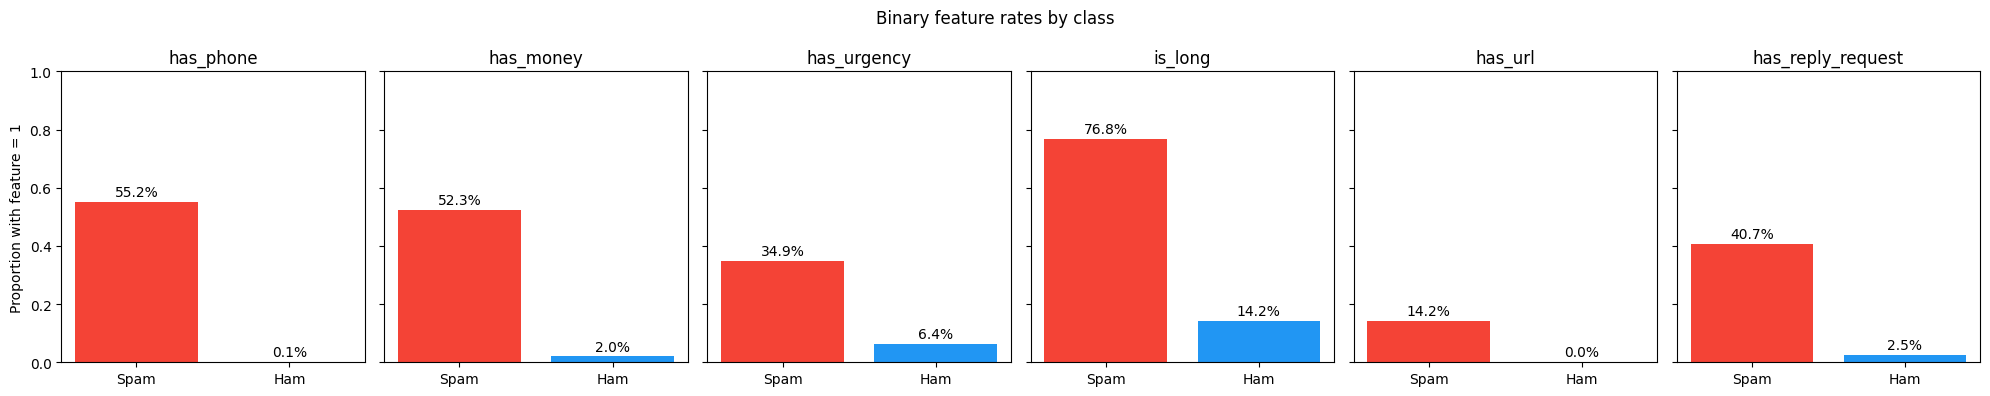

In [7]:
# Write your code here
fig, axes = plt.subplots(1, len(feature_cols), figsize=(20, 4), sharey=True)
for ax, feat in zip(axes, feature_cols):
    rates = [feature_rates.loc[1, feat], feature_rates.loc[0, feat]]
    ax.bar(['Spam', 'Ham'], rates, color=['#F44336', '#2196F3'])
    ax.set_title(feat)
    ax.set_ylim(0, 1)
    for i, rate in enumerate(rates):
        ax.text(i, rate + 0.02, f'{rate:.1%}', ha='center')
axes[0].set_ylabel('Proportion with feature = 1')
fig.suptitle('Binary feature rates by class')
plt.tight_layout()
plt.show()


### Q3 — Feature Engineering *(20 points)*

**Q3a.** Describe the two features you added.
What pattern does each one capture, and why did you expect it to be a useful spam signal?

*Feature 1 — name and explanation:*
> ... has_url: This feature is 1 when a message contains http://, https://, or www., and 0 otherwise. It captures links that may lead to fake offers, advertisements, or phishing pages. I expected it to help because spam often asks people to visit a website, although legitimate messages can contain links too.

*Feature 2 — name and explanation:*
> ... has_reply_request: This feature is 1 when a message contains the whole word txt, text, or reply, ignoring capitalization. It captures requests for the recipient to respond. Spam promotions often ask people to reply or text a keyword, making this different from the starter features for money, urgency, phone numbers, and length.

**Q3b.** Which feature has the largest gap between spam and ham?
Why does a large gap matter when a Decision Tree selects its root node?
Connect your answer to the concept of **Information Gain** from Lecture 8.

*Your answer:*
> ... is_long has the largest gap: 76.84% of spam messages are longer than 130 characters, compared with 14.16% of ham messages, a difference of about 62.69 percentage points. A large gap can produce child nodes with different class proportions and reduce uncertainty about the label. Information Gain measures the reduction in entropy after a split, so a useful separating feature can have high Information Gain. The required DecisionTreeClassifier uses Gini impurity by default, so it actually chooses splits using weighted Gini reduction rather than entropy. Its root is is_long in this run. The largest rate gap alone does not guarantee the best split because feature frequency and class weights also matter.

**Q3c.** Look at the spam examples from Step 2C.
Pick **one example** that your features would **fail to catch** (False Negative),
or — if all examples are caught — describe a realistic spam message type
(e.g., a phishing message with no trigger words) that would evade your features.
State which specific feature(s) fail and explain why.

*Your answer:*
> ... A realistic example is: “hi, this is the delivery driver. please send your door code so i can leave your parcel inside.” This could be a social engineering attempt, but all six features are 0. It has no phone number, money or urgency trigger words, URL, or whole word txt, text, or reply, and it is under 131 characters. Both fitted models classify this all-zero feature pattern as ham, so this malicious message would be a false negative. These features miss the request for sensitive information and the impersonation of a trusted person.


---
## Step 4 — Split the Data

### Step 4A — Train/Test split

**Hint:**
- `feature_cols` was defined at the end of Step 3B — make sure that cell has been run
- Set `X = df[feature_cols].values` and `y = df['spam'].values`
- Use `train_test_split` with `test_size=0.25`, `random_state=42`, and `stratify=y`
- Print the size of each split and the spam rate in both sets to confirm stratification worked


In [8]:
# Write your code here
X = df[feature_cols].values
y = df['spam'].values
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.25, random_state=42, stratify=y)
print(f'Training set: {len(y_train):,} messages; spam rate = {y_train.mean():.2%}')
print(f'Test set: {len(y_test):,} messages; spam rate = {y_test.mean():.2%}')


Training set: 4,179 messages; spam rate = 13.40%
Test set: 1,393 messages; spam rate = 13.42%


### Q4 — Data Split *(10 points)*

**Q4a. (5 points)** Why do we pass `stratify=y`?
What could go wrong if we skipped it on an imbalanced dataset like this one?

*Your answer:*
> ... stratify=y keeps the spam and ham proportions approximately equal across the training and test sets. The training set has 4,179 messages with 13.40% spam, and the test set has 1,393 messages with 13.42% spam. Without stratification, a random split could contain too few spam examples in one set, especially with a smaller dataset, making training or evaluation less reliable.

**Q4b. (5 points)** We use a 75/25 train/test split.
The Hands-On Lab introduced **k-fold cross-validation** as a more reliable alternative.
Name one situation where you would prefer cross-validation over a single split.

*Your answer:*
> ... I would prefer cross-validation when comparing tree depths or other model settings on a limited dataset. A single split may favor a model just because of which examples ended up in the test set. Stratified k-fold cross-validation evaluates each setting across several training and validation splits and shows how consistent the results are. I would use only the training data for that comparison and keep the test set for final evaluation.


---
## Step 5 — Train the Models （Each code 5 pts）

### Step 5A — Decision Tree

**Hint:**
- Use `DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')`
- Fit on the training set
- Print the number of leaves with `.get_n_leaves()`
- Visualize the tree with `plot_tree(..., feature_names=..., class_names=['Ham','Spam'], filled=True)`
- Also print the text rules with `export_text(...)`


Number of leaves: 14


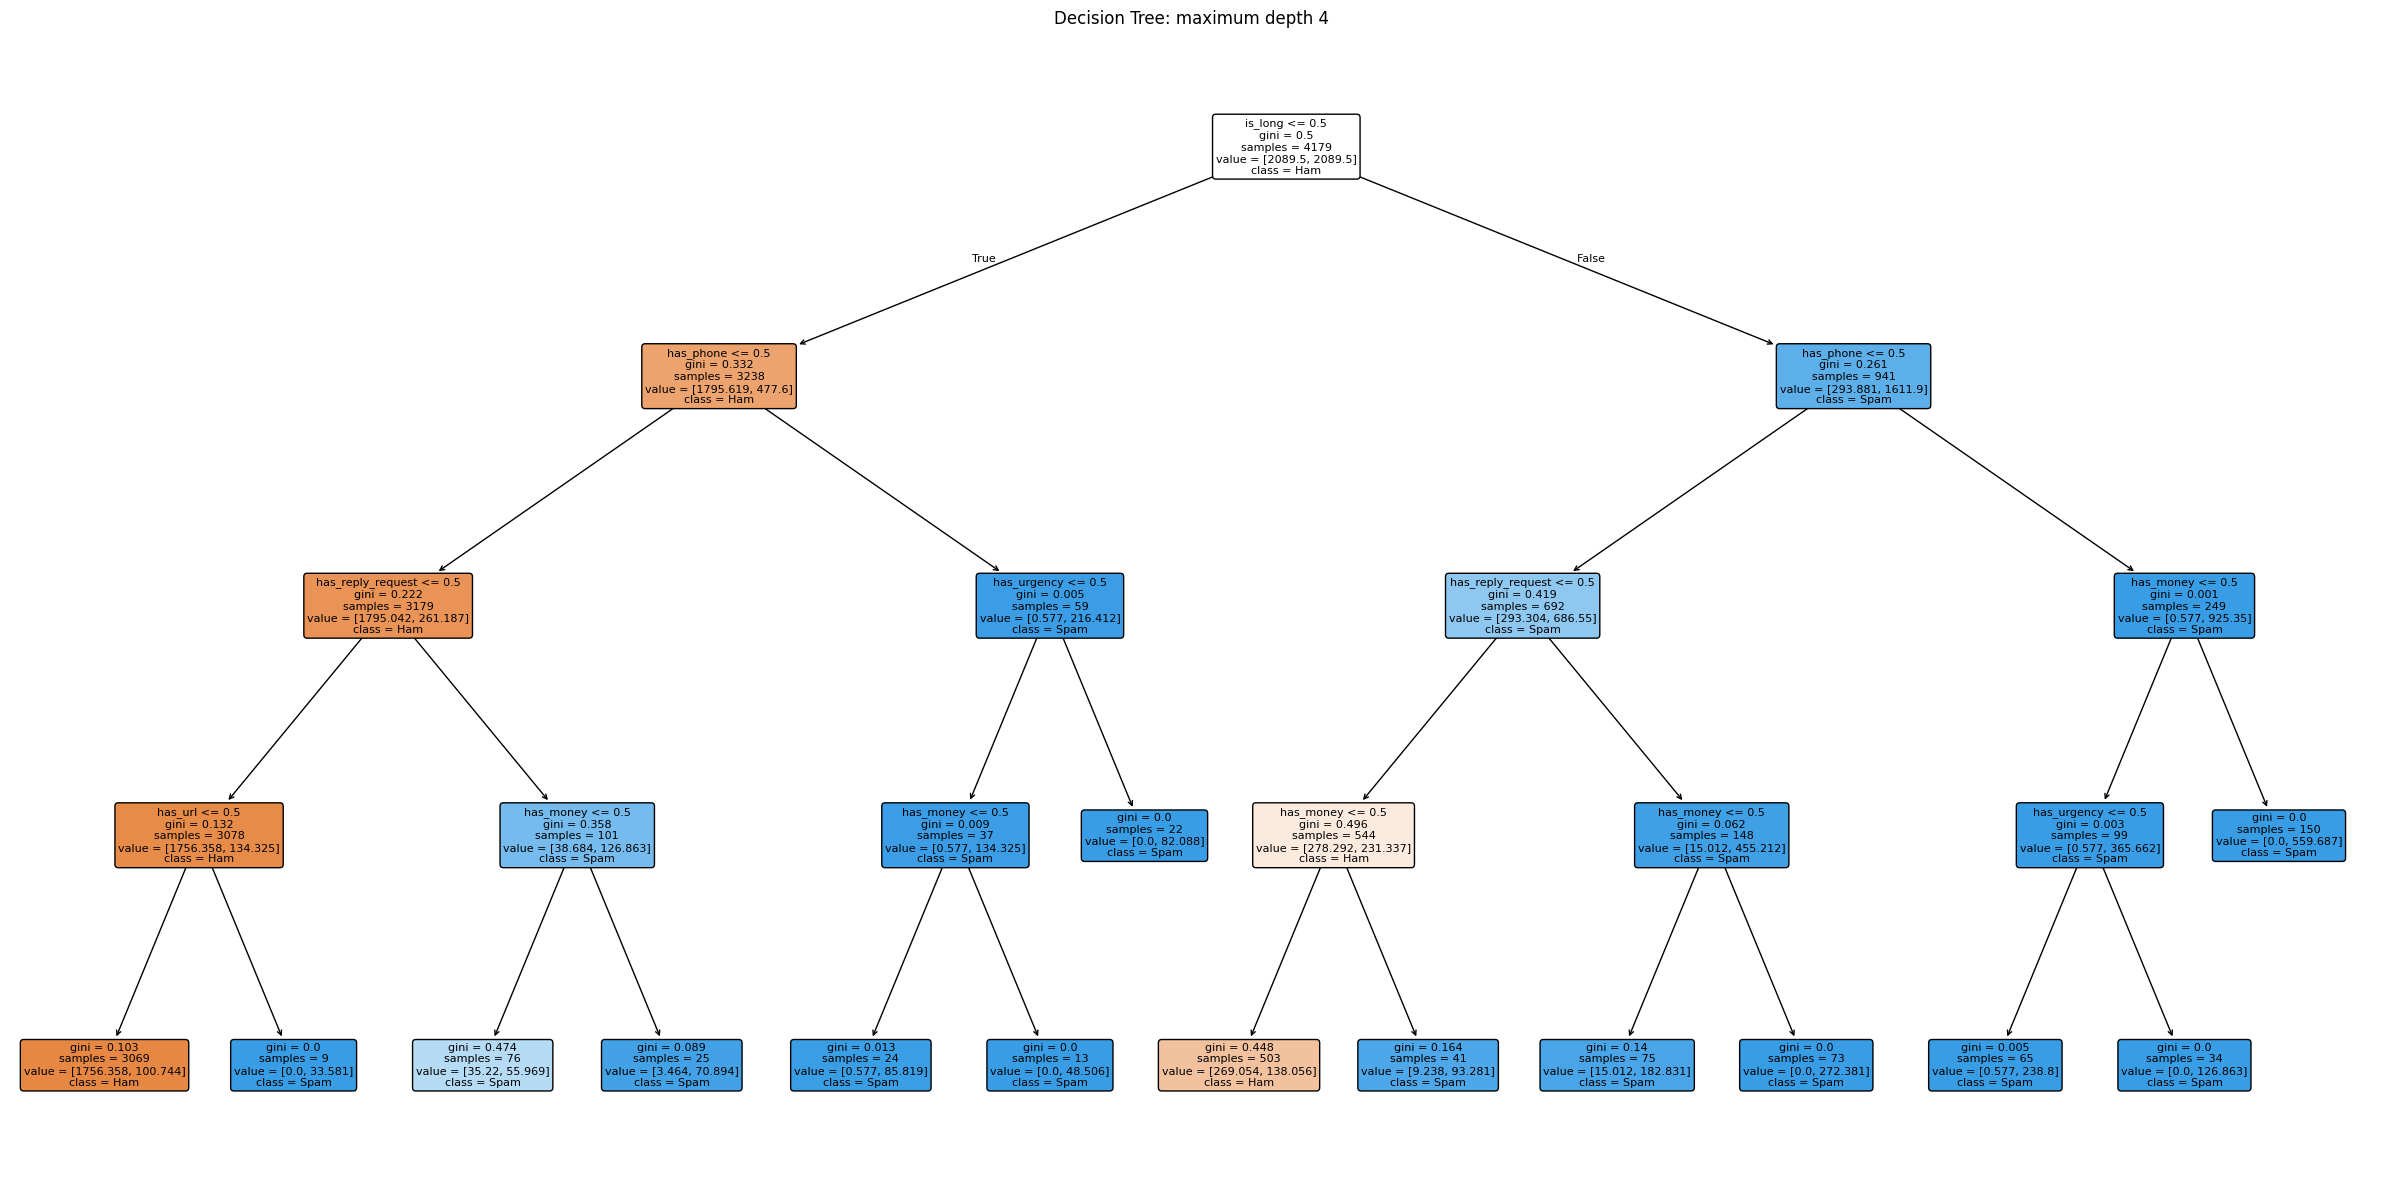

|--- is_long <= 0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_request <= 0.50
|   |   |   |--- has_url <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_url >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_request >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |--- has_phone >  0.50
|   |   |--- has_urgency <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_urgency >  0.50
|   |   |   |--- class: 1
|--- is_long >  0.50
|   |--- has_phone <= 0.50
|   |   |--- has_reply_request <= 0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 0
|   |   |   |--- has_money >  0.50
|   |   |   |   |--- class: 1
|   |   |--- has_reply_request >  0.50
|   |   |   |--- has_money <= 0.50
|   |   |   |   |--- class: 1
|   |   |   |--- has_money >  0.50
|   |   |   |

In [9]:
# Write your code here
dt = DecisionTreeClassifier(max_depth=4, random_state=42, class_weight='balanced')
dt.fit(X_train, y_train)
print(f'Number of leaves: {dt.get_n_leaves()}')
plt.figure(figsize=(24, 12))
plot_tree(dt, feature_names=feature_cols, class_names=['Ham', 'Spam'],
          filled=True, rounded=True, fontsize=8)
plt.title('Decision Tree: maximum depth 4')
plt.tight_layout()
plt.show()
print(export_text(dt, feature_names=feature_cols))


### Step 5B — Feature Importance

**Hint:**
- Get `.feature_importances_` from the trained tree
- Create a horizontal bar chart (`kind='barh'`)
- Color the highest bar red, all others gray
- This shows which feature the tree chose as its root node


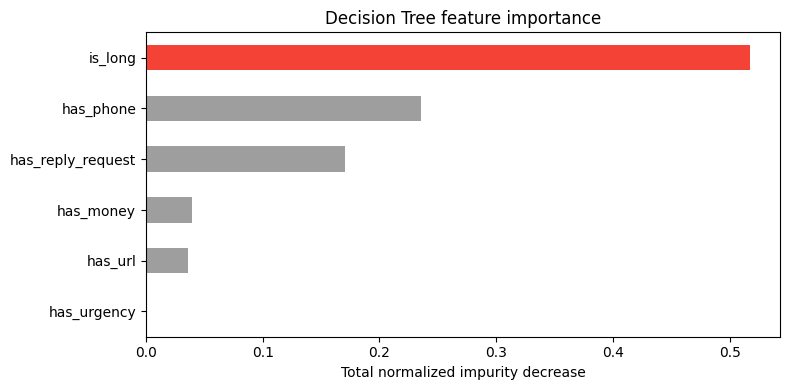

Actual root feature: is_long
Highest overall importance: is_long
Importance sums contributions across the tree; it does not necessarily identify the root.


In [10]:
# Write your code here
importance = pd.Series(dt.feature_importances_, index=feature_cols).sort_values()
colors = ['#F44336' if name == importance.idxmax() else '#9E9E9E'
          for name in importance.index]
importance.plot(kind='barh', color=colors, figsize=(8, 4))
plt.xlabel('Total normalized impurity decrease')
plt.title('Decision Tree feature importance')
plt.tight_layout()
plt.show()
root_feature = feature_cols[dt.tree_.feature[0]]
print(f'Actual root feature: {root_feature}')
print(f'Highest overall importance: {importance.idxmax()}')
print('Importance sums contributions across the tree; it does not necessarily identify the root.')


### Step 5C — Effect of Tree Depth

**Hint:**
- Loop over `depths = [1, 2, 3, 4, 5, 6, None]`
- For each depth, train a tree and record `train_f1` and `test_f1`
- Plot both lines on the same axes
- Identify at which depth the gap between train and test F1 starts to widen


    Depth  Train F1  Test F1  Train minus test F1
        1    0.5756   0.5646               0.0110
        2    0.6282   0.6210               0.0073
        3    0.8272   0.8347              -0.0075
        4    0.8500   0.8527              -0.0027
        5    0.8617   0.8615               0.0002
        6    0.8591   0.8593              -0.0003
Unlimited    0.8591   0.8593              -0.0003


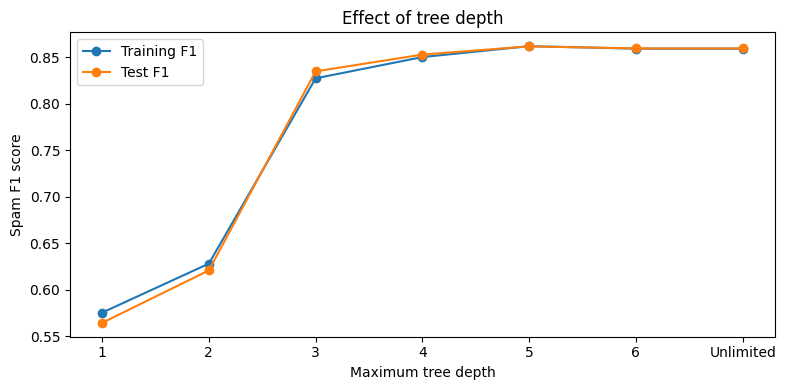

No substantial widening (> 0.005) in the signed train/test gap.
These test curves are descriptive. Use training cross-validation for depth selection.


In [11]:
# Write your code here
depths = [1, 2, 3, 4, 5, 6, None]
depth_rows = []
for depth in depths:
    model = DecisionTreeClassifier(max_depth=depth, random_state=42,
                                   class_weight='balanced')
    model.fit(X_train, y_train)
    depth_rows.append({'Depth': str(depth) if depth is not None else 'Unlimited',
                      'Train F1': f1_score(y_train, model.predict(X_train), zero_division=0),
                      'Test F1': f1_score(y_test, model.predict(X_test), zero_division=0)})
depth_results = pd.DataFrame(depth_rows)
depth_results['Train minus test F1'] = depth_results['Train F1'] - depth_results['Test F1']
print(depth_results.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
plt.figure(figsize=(8, 4))
plt.plot(depth_results['Depth'], depth_results['Train F1'], 'o-', label='Training F1')
plt.plot(depth_results['Depth'], depth_results['Test F1'], 'o-', label='Test F1')
plt.xlabel('Maximum tree depth')
plt.ylabel('Spam F1 score')
plt.title('Effect of tree depth')
plt.legend()
plt.tight_layout()
plt.show()
gaps = depth_results['Train minus test F1'].to_numpy()
widening = np.flatnonzero(np.diff(gaps) > 0.005) + 1
if len(widening):
    j = widening[0]
    print(f'First widening greater than 0.005: depth {depth_results.loc[j, "Depth"]} '
          f'(gap {gaps[j-1]:.4f} to {gaps[j]:.4f}).')
else:
    print('No substantial widening (> 0.005) in the signed train/test gap.')
print('These test curves are descriptive. Use training cross-validation for depth selection.')


### Step 5D — Naive Bayes

**Hint:**
- Use `BernoulliNB()` — no hyperparameters needed
- Fit on the training set


In [12]:
# Write your code here
nb = BernoulliNB()
nb.fit(X_train, y_train)
print(f'Bernoulli Naive Bayes trained on {X_train.shape[0]:,} messages and {X_train.shape[1]} binary features.')


Bernoulli Naive Bayes trained on 4,179 messages and 6 binary features.


---
## Step 6 — Evaluate *(Each code block 4 points)*

### Step 6A — Confusion Matrices

**Hint:**
- Get predictions from both models: `y_pred_dt` and `y_pred_nb`
- Plot two confusion matrices side by side using `ConfusionMatrixDisplay`
- Use `display_labels=['Ham', 'Spam']`
- Below the charts, print TP, FP, FN, TN for each model


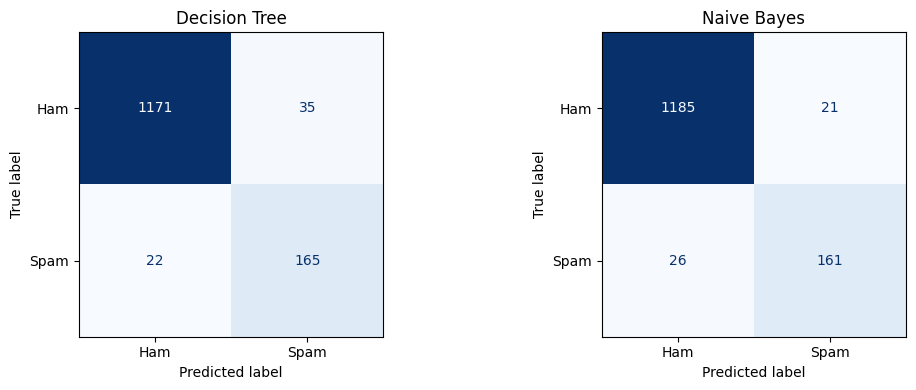

Decision Tree: TP = 165, FP = 35, FN = 22, TN = 1171
Naive Bayes: TP = 161, FP = 21, FN = 26, TN = 1185


In [13]:
# Write your code here
y_pred_dt = dt.predict(X_test)
y_pred_nb = nb.predict(X_test)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
confusion_counts = {}
for ax, name, pred in zip(axes, ['Decision Tree', 'Naive Bayes'], [y_pred_dt, y_pred_nb]):
    cm = confusion_matrix(y_test, pred, labels=[0, 1])
    ConfusionMatrixDisplay(cm, display_labels=['Ham', 'Spam']).plot(
        ax=ax, cmap='Blues', colorbar=False, values_format='d')
    ax.set_title(name)
    tn, fp, fn, tp = cm.ravel()
    confusion_counts[name] = {'TP': int(tp), 'FP': int(fp), 'FN': int(fn), 'TN': int(tn)}
plt.tight_layout()
plt.show()
for name, counts in confusion_counts.items():
    print(f'{name}: ' + ', '.join(f'{key} = {val}' for key, val in counts.items()))


### Step 6B — Metrics Comparison

**Hint:**
- Build a DataFrame with columns: Model, Accuracy, Precision, Recall, F1-Score
- One row per model
- Also create a grouped bar chart comparing all four metrics side by side


        Model  Accuracy  Precision  Recall  F1-Score
Decision Tree    0.9591     0.8250  0.8824    0.8527
  Naive Bayes    0.9663     0.8846  0.8610    0.8726


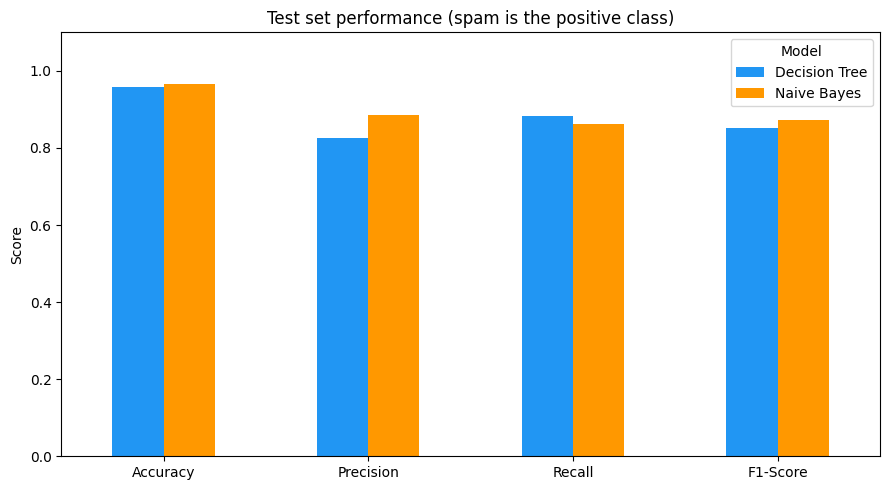

In [14]:
# Write your code here
metric_rows = []
for name, pred in [('Decision Tree', y_pred_dt), ('Naive Bayes', y_pred_nb)]:
    metric_rows.append({'Model': name,
                        'Accuracy': accuracy_score(y_test, pred),
                        'Precision': precision_score(y_test, pred, zero_division=0),
                        'Recall': recall_score(y_test, pred, zero_division=0),
                        'F1-Score': f1_score(y_test, pred, zero_division=0)})
metrics = pd.DataFrame(metric_rows)
print(metrics.to_string(index=False, float_format=lambda v: f'{v:.4f}'))
metrics.set_index('Model').T.plot(kind='bar', figsize=(9, 5), rot=0,
                                 color=['#2196F3', '#FF9800'])
plt.ylim(0, 1.1)
plt.ylabel('Score')
plt.title('Test set performance (spam is the positive class)')
plt.legend(title='Model')
plt.tight_layout()
plt.show()


### Step 6C — Cross-Validation

**Hint:**
- Use `StratifiedKFold(n_splits=5, shuffle=True, random_state=42)`
- Run `cross_val_score` with `scoring='f1'` for both models
- Print the average F1 across 5 folds for each model


In [15]:
# Write your code here
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_results = {}
# Cross-validate only within the training set so the test set stays held out.
for name, model in [('Decision Tree', dt), ('Naive Bayes', nb)]:
    f1_scores = cross_val_score(model, X_train, y_train, cv=cv, scoring='f1')
    precision_scores = cross_val_score(model, X_train, y_train, cv=cv,
                                     scoring='precision')
    cv_results[name] = {'f1': f1_scores.tolist(), 'precision': precision_scores.tolist()}
    print(f'{name}:')
    print(f'  Fold F1 scores: {np.round(f1_scores, 4)}')
    print(f'  Mean F1: {f1_scores.mean():.4f} (SD = {f1_scores.std():.4f})')
    print(f'  Mean precision: {precision_scores.mean():.4f} (SD = {precision_scores.std():.4f})')
print('Precision is also cross-validated because it is the primary metric from Q1b.')


Decision Tree:
  Fold F1 scores: [0.8509 0.8412 0.8783 0.834  0.8465]
  Mean F1: 0.8502 (SD = 0.0151)
  Mean precision: 0.8179 (SD = 0.0246)
Naive Bayes:
  Fold F1 scores: [0.8716 0.8739 0.9182 0.8796 0.886 ]
  Mean F1: 0.8858 (SD = 0.0169)
  Mean precision: 0.8995 (SD = 0.0229)
Precision is also cross-validated because it is the primary metric from Q1b.


### Q6 — Evaluation & Analysis *(25 points)*

> **Points breakdown:**
> - Step 6A code (runs correctly): 4 pts
> - Step 6B code (runs correctly): 4 pts
> - Step 6C code (runs correctly): 4 pts
> - Q6a written: 3 pts
> - Q6b written: 3 pts
> - Q6c written: 4 pts
> - Q6d written: 3 pts
> - **Total: 25 pts**

---

**Q6a. Read the confusion matrices (Step 6A) — *(3 points)***

For each model, state:
- How many spam messages were correctly caught (True Positives)?
- How many spam messages slipped through (False Negatives)?
- How many legitimate messages were wrongly blocked (False Positives)?

*Decision Tree:*
> ... The Decision Tree correctly caught 165 spam messages, missed 22 spam messages, and wrongly blocked 35 legitimate messages. It correctly accepted 1,171 ham messages.

*Naive Bayes:*
> ...Naive Bayes correctly caught 161 spam messages, missed 26 spam messages, and wrongly blocked 21 legitimate messages. It correctly accepted 1,185 ham messages.

**Q6b. Apply your metric from Q1b — *(3 points)***

Which model wins on the metric you chose in Step 1?
By how much? Does the cross-validation result (Step 6C) confirm this?

*Your answer:*
> ... Naive Bayes wins on precision: 88.46% compared with 82.50% for the Decision Tree, a difference of 5.96 percentage points. The required five-fold F1 comparison also favors Naive Bayes, with mean F1 of 0.8858 versus 0.8502, but F1 alone does not confirm which model has higher precision. I therefore also cross-validated precision on the training data: Naive Bayes averaged 89.95%, compared with 81.79% for the tree. This supports the same model choice across folds, although it is not a guarantee for future messages.

**Q6c. Recommendation memo — *(4 points)***

Imagine you are presenting to a product manager at a mobile carrier.
Write 4–5 sentences that:
1. State which model you recommend
2. Justify the choice with one specific number from your results
3. Acknowledge one weakness of your recommended model
4. Propose one concrete improvement

*Your memo:*
> ... I recommend Naive Bayes because our main priority is avoiding blocked legitimate messages. Its test precision was 88.46%, and it wrongly blocked 21 legitimate messages compared with 35 for the Decision Tree. Its weakness is that it missed 26 spam messages, four more than the tree. I would add word and character n-gram features using recent labeled messages to capture patterns beyond the six binary indicators. I would test that improvement with stratified cross-validation on the training data while tracking precision and recall before evaluating it on a new held-out set.

**Q6d. Generalization — *(3 points)***

The SMS Spam Collection was collected in the early 2010s.
Modern spam often uses professional language and legitimate-looking URLs.
Identify **two features you built** that would likely fail on modern spam, and explain why.

*Your answer:*
> ... has_money can miss modern spam that avoids words such as free, winner, prize, and claim. A message impersonating a delivery service or employer may request personal information without using any of those words. has_reply_request can also miss messages that say “review the document” or “verify your details” without using txt, text, or reply. Even has_url only detects the presence of certain URL formats; it cannot tell whether a professional-looking link is trustworthy. These features can still help, but they do not capture the meaning or intent of a message.
